# Pangolin GPU Planner – AI Inference Capacity & Cost Sizing (notebook)

This notebook uses the **same sizing engine and data** as the web app ([`index.html`](../index.html)), ported to Python in [`python/pangolin_planner.py`](../python/pangolin_planner.py). Models, GPUs and assumptions are read from [`js/data.js`](../js/data.js), so the notebook and the browser always agree.

Use it to:
1. browse the model and GPU data
2. size a single workload and compare all GPUs
3. run **sweeps** (e.g. GPUs needed vs. concurrent users) that are tedious in the UI
4. build a **multi-workload plan**, including from scenarios exported from the web app
5. explore **rough** cost sensitivity
6. export results to Excel

> ⚠️ **Caveat emptor:** all cost figures are rough indicative ranges for early budgeting only, not quotes. They may be wrong by ±30–50% or more.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "python"))   # run from the notebooks/ folder
import pandas as pd
import matplotlib.pyplot as plt
import pangolin_planner as pp

pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
print("Engine", pp.__version__, "| data reviewed", pp.DATA["dataDate"], "|", len(pp.DATA["models"]), "models,", len(pp.DATA["gpus"]), "GPUs")

Engine 2.0.0 | data reviewed November 2026 | 25 models, 22 GPUs


## 1. Data
Models: `total`/`active` parameters in billions, `kv` = KV-cache KiB per token at FP16, `state` = fixed MB per user (linear-attention layers), `est` = size not published (placeholder).

In [2]:
pp.models_table()

,id,name,total,active,kv,state,open,est
0,mistral7b,Mistral-7B-v0.3,7.25,7.25,128.000,NaN,True,None
1,llama2-7b,Llama-2-7B,6.74,6.74,512.000,NaN,True,None
2,llama2-13b,Llama-2-13B,13.00,13.00,800.000,NaN,True,None
3,llama3-8b,Llama-3-8B,8.03,8.03,128.000,NaN,True,None
4,llama31-8b,Llama-3.1-8B,8.03,8.03,128.000,NaN,True,None
5,gpt61-terra,GPT-6.1-Terra,1200.00,60.00,100.000,NaN,False,True
6,gpt62-sol,GPT-6.2-Sol,800.00,40.00,100.000,NaN,False,True
7,gpt62-astra,GPT-6.2-Astra,2000.00,100.00,120.000,NaN,False,True
8,gpt6-luna,GPT-6-Luna,300.00,15.00,60.000,NaN,False,True
9,kimi-k31,Kimi K3.1-Pro,2780.00,104.00,27.000,434.0,True,None


GPUs: `mem` = usable GB (`memRaw` = marketed), `bw` = GB/s, dense tensor TFLOPS per precision (`fp32` = TF32), `tdp` in W, `price` = rough USD range per GPU.

In [3]:
pp.gpus_table()

,id,name,vendor,arch,form,mem,memRaw,bw,fp16,fp8,fp4,fp32,tdp,price
0,a10,NVIDIA A10,NVIDIA,Ampere,PCIe,24,NaN,600,125,250,0,62,150,"[2000, 4000]"
1,a30,NVIDIA A30,NVIDIA,Ampere,PCIe,24,NaN,933,165,330,0,82,165,"[4000, 7000]"
2,a40,NVIDIA A40,NVIDIA,Ampere,PCIe,48,NaN,696,150,300,0,75,300,"[4000, 7000]"
3,a100,NVIDIA A100 80GB,NVIDIA,Ampere,SXM,80,NaN,2039,312,624,0,156,400,"[8000, 17000]"
4,l4,NVIDIA L4,NVIDIA,Ada,PCIe,24,NaN,300,121,242,0,60,72,"[2000, 3500]"
5,l40,NVIDIA L40,NVIDIA,Ada,PCIe,48,NaN,864,181,362,0,90,300,"[6000, 9000]"
6,l40s,NVIDIA L40S,NVIDIA,Ada,PCIe,48,NaN,864,362,733,0,183,350,"[7000, 11000]"
7,h100,NVIDIA H100 SXM,NVIDIA,Hopper,SXM,80,NaN,3350,989,1979,0,495,700,"[25000, 40000]"
8,h100pcie,NVIDIA H100 PCIe,NVIDIA,Hopper,PCIe,80,NaN,2000,756,1513,0,378,350,"[22000, 32000]"
9,h100nvl,NVIDIA H100 NVL,NVIDIA,Hopper,PCIe,94,NaN,3900,835,1671,0,418,400,"[25000, 35000]"


## 2. Size one workload
Inputs use the same keys as the web app (`default_inputs()` gives the spreadsheet defaults). Example: Llama-3.1-8B chatbot, 1,000 concurrent users at 30 tokens/s, FP8, 8 GPUs per server, N+1 redundancy.

In [4]:
inp = pp.default_inputs(model="llama31-8b", prec="FP8", users=1000, tps=30, gpu="h100",
                        isl=1024, osl=512, gps=8, util=90, redund="n1")
R = pp.compute_all(inp)
s, b = R["sel"], R["best"]
print(f"Selected {s['gpu']['name']}: {s['gpus']} GPUs ({s['spareGpus']} spare), {s['servers']} servers, "
      f"{s['totalGpuMemRaw']:,} GB GPU memory, {s['totalTflops']:,.0f} TFLOPS, host RAM {s['hostRecGB']:,} GB/server, "
      f"{s['facKW']:.1f} kW, ~{s['perUserTps']:.0f} tok/s/user, limited by {s['limit']}")
print(f"Recommended: {b['gpu']['name']} x {b['gpus']} ({b['servers']} servers, {b['facKW']:.1f} kW)")

Selected NVIDIA H100 SXM: 10 GPUs (8 spare), 2 servers, 800 GB GPU memory, 19,790 TFLOPS, host RAM 1,536 GB/server, 11.8 kW, ~40 tok/s/user, limited by Memory capacity
Recommended: NVIDIA A10 x 16 (2 servers, 4.1 kW)


In [5]:
cmp = pp.comparison_table(R)
cmp

,rank,gpu,vendor,form,memory_GB,gpus_per_copy,total_gpus,spare_gpus,servers,total_gpu_mem_GB,total_TFLOPS,host_RAM_per_server_GB,facility_kW,tok_s_per_user,hw_cost_low_$,hw_cost_high_$,tco_low_$,tco_high_$,limited_by
0,1,NVIDIA A10,NVIDIA,PCIe,24,8,16,8,2,384,4000,384,4.06,30.9,90200,220800,119523,311160,Model weights (minimum footprint)
1,2,NVIDIA A30,NVIDIA,PCIe,24,2,16,8,2,384,5280,384,4.46,39.3,125400,278400,163938,390584,Memory capacity
2,3,NVIDIA H100 PCIe,NVIDIA,PCIe,80,1,11,8,2,880,16643,1536,6.51,33.7,321200,566400,410599,787745,Memory bandwidth (token speed)
3,4,NVIDIA H100 NVL,NVIDIA,PCIe,94,1,10,8,2,940,16710,1536,6.76,46.8,330000,564000,421991,785161,Memory capacity
4,5,NVIDIA A100 80GB,NVIDIA,SXM,80,1,11,8,2,880,6864,1536,7.44,34.3,272800,584400,352342,814717,Memory bandwidth (token speed)
5,6,NVIDIA A40,NVIDIA,PCIe,48,4,16,8,2,768,4800,768,8.11,33.4,125400,278400,170845,400369,Memory bandwidth (token speed)
6,7,NVIDIA L40,NVIDIA,PCIe,48,2,16,8,2,768,5792,768,8.11,36.4,160600,316800,214493,452593,Memory bandwidth (token speed)
7,8,NVIDIA H200 NVL,NVIDIA,PCIe,141,1,9,8,2,1269,15039,3072,9.13,30.9,332200,576000,429196,807823,Model weights (minimum footprint)
8,9,NVIDIA L40S,NVIDIA,PCIe,48,2,16,8,2,768,11728,768,9.46,36.4,178200,355200,238875,508441,Memory bandwidth (token speed)
9,10,NVIDIA H200 SXM,NVIDIA,SXM,141,1,9,8,2,1269,17811,3072,10.65,30.9,473000,954000,606666,1325980,Model weights (minimum footprint)


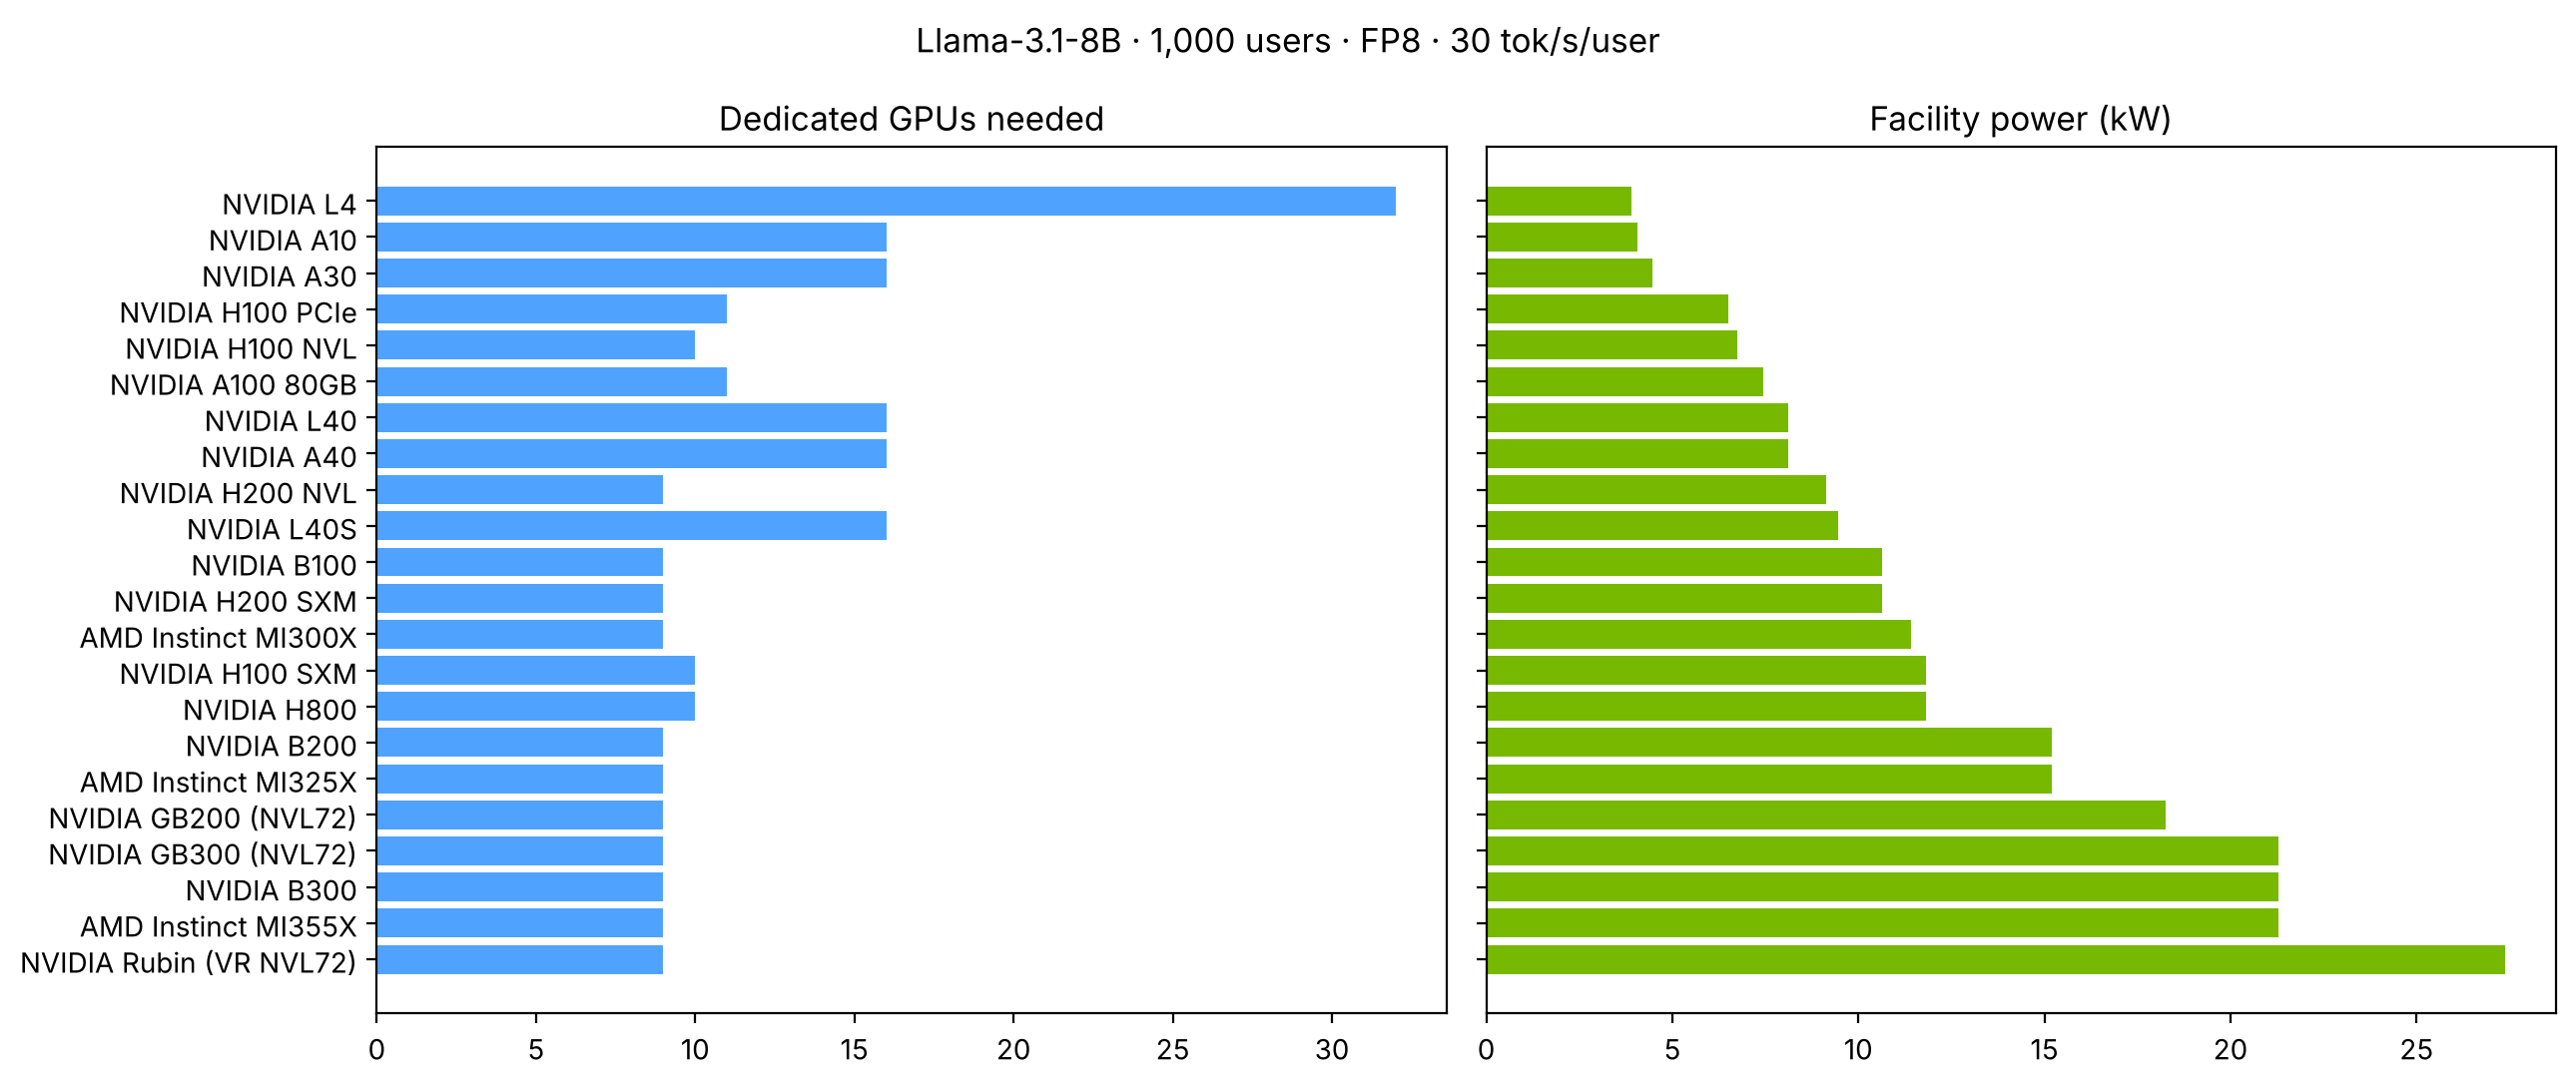

In [6]:
ok = cmp.dropna(subset=["total_gpus"]).sort_values("facility_kW")
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
ax[0].barh(ok["gpu"], ok["total_gpus"], color="#4fa3ff"); ax[0].set_title("Dedicated GPUs needed"); ax[0].invert_yaxis()
ax[1].barh(ok["gpu"], ok["facility_kW"], color="#76b900"); ax[1].set_title("Facility power (kW)"); ax[1].invert_yaxis()
ax[1].set_yticklabels([])
fig.suptitle(f"{R['model']['name']} · {inp['users']:,} users · {inp['prec']} · {inp['tps']} tok/s/user")
plt.tight_layout(); plt.show()

## 3. Sweep: GPUs needed vs. concurrent users
Sweeps answer "when do we need the next server?". This one sizes GLM-5.3 at FP8, 30 tok/s per user, across user counts on four GPUs.

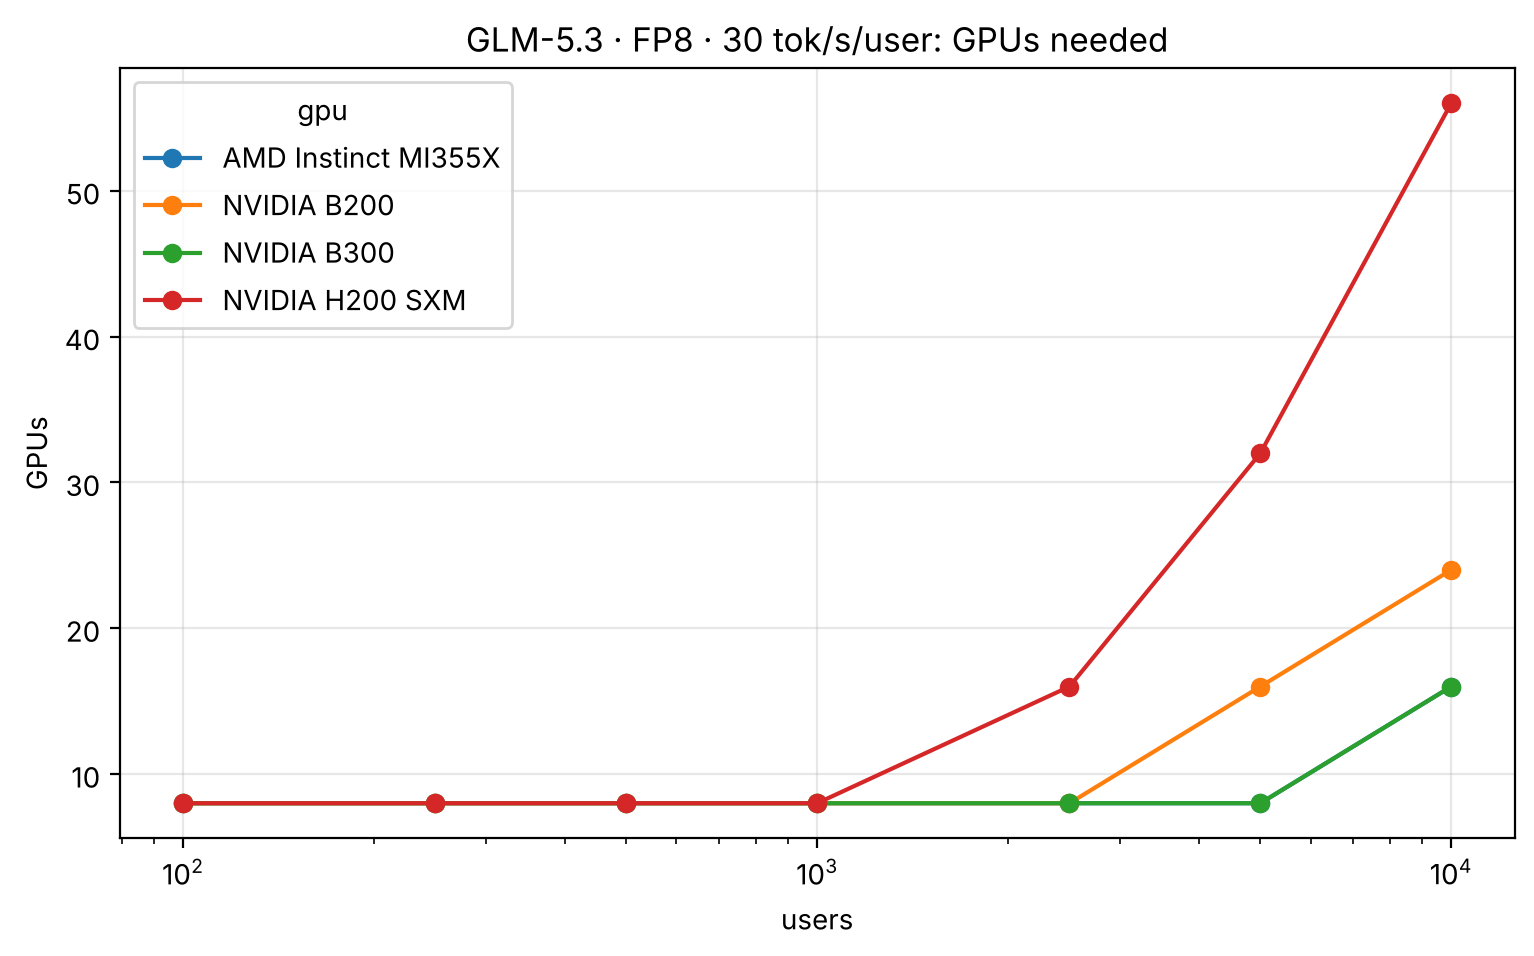

gpu,AMD Instinct MI355X,NVIDIA B200,NVIDIA B300,NVIDIA H200 SXM
users,,,,
100,8,8,8,8
250,8,8,8,8
500,8,8,8,8
1000,8,8,8,8
2500,8,8,8,16
5000,8,16,8,32
10000,16,24,16,56


In [7]:
sw = pp.sweep(pp.default_inputs(model="glm53", prec="FP8", tps=30, gps=8, util=90),
              "users", [100, 250, 500, 1000, 2500, 5000, 10000], gpus=["h200", "b200", "b300", "mi355x"])
piv = sw.pivot(index="users", columns="gpu", values="gpus")
ax = piv.plot(marker="o", logx=True, figsize=(9, 5), title="GLM-5.3 · FP8 · 30 tok/s/user: GPUs needed")
ax.set_ylabel("GPUs"); ax.grid(alpha=.3); plt.show()
piv

Precision sweep: how much do FP8 and FP4 save for a large MoE model (Kimi K3.1-Pro, 2,000 users)?

In [8]:
psw = pp.sweep(pp.default_inputs(model="kimi-k31", users=2000, tps=20, gps=8, util=90),
               "prec", ["FP16", "FP8", "FP4"], gpus=["h200", "b200", "b300", "gb300", "mi355x"])
psw.pivot(index="gpu", columns="prec", values="gpus")[["FP16", "FP8", "FP4"]]

prec,FP16,FP8,FP4
gpu,,,
AMD Instinct MI355X,32,16,16
NVIDIA B200,64,32,16
NVIDIA B300,32,24,24
NVIDIA GB300 (NVL72),32,24,24
NVIDIA H200 SXM,64,40,24


## 4. Multi-workload plan
Define several workloads (or load scenarios exported from the web app with `pp.load_scenarios('pangolin-gpu-planner-scenarios.json')`). Each runs on its own selected GPU, and the plan also shows the best single GPU type for everything.

In [9]:
scenarios = [
    {"name": "Chatbot",        "inp": pp.default_inputs(model="llama31-8b", prec="FP8", users=2000, tps=30, gpu="h200", gps=8, util=90, redund="n1")},
    {"name": "Code assistant", "inp": pp.default_inputs(model="qwen38-27b", prec="FP8", users=500, isl=2048, osl=1024, tps=50, gpu="h200", gps=8, util=90, redund="n1")},
    {"name": "Agentic (MoE)",  "inp": pp.default_inputs(model="glm53", prec="FP8", users=1000, isl=8192, osl=2048, tps=30, gpu="b300", gps=8, util=90, redund="n1")},
    {"name": "Doc summaries",  "inp": pp.default_inputs(model="deepseek-v41", prec="FP8", users=5000, isl=8192, osl=512, tps=20, gpu="b300", gps=8, util=90, redund="p10")},
]
P = pp.plan(scenarios)
P["workloads"]

,workload,model,precision,users,gpu,gpus,servers,gpu_memory_GB,host_RAM_total_GB,facility_kW,hw_cost_low_$,hw_cost_high_$,limited_by
0,Chatbot,Llama-3.1-8B,FP8,2000,NVIDIA H200 SXM,11,2,1551,6144,13.01,539000,1086000,Memory capacity
1,Code assistant,Qwen 3.8-27B,FP8,500,NVIDIA H200 SXM,10,2,1410,6144,11.83,506000,1020000,Model weights (minimum footprint)
2,Agentic (MoE),GLM-5.3,FP8,1000,NVIDIA B300,16,2,4608,8192,37.86,880000,1896000,Model weights (minimum footprint)
3,Doc summaries,DeepSeek V4.1 (Flash),FP8,5000,NVIDIA B300,8,1,2304,4096,18.93,440000,948000,Model weights (minimum footprint)


In [10]:
print("PLAN TOTALS"); print(P["totals"].to_string())
P["single_gpu_options"].head(8)

PLAN TOTALS
gpus                      45.00
servers                    7.00
gpu_memory_GB           9873.00
host_RAM_total_GB      24576.00
facility_kW               81.63
hw_cost_low_$        2365000.00
hw_cost_high_$       4950000.00


,gpu,gpus,servers,facility_kW,feasible
0,NVIDIA B300,44,7,104.1040,True
1,NVIDIA GB300 (NVL72),44,7,104.1040,True
2,AMD Instinct MI355X,44,7,104.1040,True
3,NVIDIA Rubin (VR NVL72),43,7,130.8060,True
4,NVIDIA B100,52,8,61.5160,True
5,AMD Instinct MI325X,52,8,87.8800,True
6,NVIDIA GB200 (NVL72),52,8,105.4560,True
7,AMD Instinct MI300X,61,9,77.3175,True


## 5. Rough cost sensitivity
> ⚠️ Rough indicative ranges only (see caveat above). Change `cost=` to match your electricity price, ownership period and utilisation, or override the GPU price with `plo`/`phi` (and `gpu`).

In [11]:
print(pp.COST_CAVEAT, "\n")
rows = []
for kwh in (0.08, 0.12, 0.20):
    for years in (3, 5):
        i = pp.default_inputs(model="llama31-8b", prec="FP8", users=2000, tps=30, gpu="h200", gps=8, util=90,
                              redund="n1", cost={"kwh": kwh, "years": years, "util": 50})
        c = pp.compute_all(i)["sel"]["cost"]
        rows.append({"$/kWh": kwh, "years": years, "TCO low": round(c["tcoLo"]), "TCO high": round(c["tcoHi"]),
                     "$/1M tokens low": round(c["perMLo"], 3), "$/1M tokens high": round(c["perMHi"], 3)})
pd.DataFrame(rows)

CAVEAT EMPTOR: cost figures are rough indicative ranges for early budgeting and relative comparison only. They are not quotes and may be wrong by ±30–50% or more. GPU, server, network and energy prices change quickly and vary with supplier, volume, contract terms, region, configuration and availability. Excluded: facility build-out, cooling plant, software licences, staffing, taxes, financing. 



,$/kWh,years,TCO low,TCO high,$/1M tokens low,$/1M tokens high
0,0.08,3,684775,1500215,0.210,0.460
1,0.08,5,781959,1776358,0.144,0.327
2,0.12,3,692983,1511842,0.213,0.464
3,0.12,5,795638,1795737,0.146,0.330
4,0.20,3,709398,1535097,0.218,0.471
5,0.20,5,822996,1834495,0.151,0.338


## 6. Export
Write the comparison and plan to an Excel workbook (`openpyxl` required). The `Notes` sheet carries the cost caveat.

In [12]:
out = pathlib.Path("pangolin_gpu_planner_notebook_export.xlsx")
with pd.ExcelWriter(out) as xw:
    cmp.to_excel(xw, sheet_name="GPU comparison", index=False)
    P["workloads"].to_excel(xw, sheet_name="Plan", index=False)
    P["single_gpu_options"].to_excel(xw, sheet_name="Single GPU options", index=False)
    pd.DataFrame({"Notes": [pp.COST_CAVEAT, "Data reviewed " + pp.DATA["dataDate"]]}).to_excel(xw, sheet_name="Notes", index=False)
print("Wrote", out.resolve())

Wrote /home/claude/pgp/notebooks/pangolin_gpu_planner_notebook_export.xlsx


## Notes
* The engine is a line-by-line port of `js/app.js`. `tests/test_engine.py` pins reference results so the two stay in step.
* To add or correct a model or GPU, edit `js/data.js`. The web app and this notebook both pick it up.
* Method and assumptions: see the README and the *Method & assumptions* section of any web report.